<a href="https://colab.research.google.com/github/AlessiaSerra/Clickbait-Detection/blob/main/ClickBaitDetection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
pip install datasets pandas scikit-learn numpy

--> Caricamento del dataset da Hugging Face...
--> Elaborazione di 1000 istanze per estrazione delle feature AIT...

EXPLORATORY DATA ANALYSIS: UNEXPECTEDNESS vs CLICKBAIT
           C_d                       C_w                        U                      U_norm                    
          mean        std median    mean       std median    mean        std median      mean       std    median
label                                                                                                            
0      108.704  14.505903  108.0   3.624  1.168484    4.0 -105.08  14.368246 -104.0 -2.160891  0.457612 -2.080000
1      114.976  16.342263  114.0  28.176  8.578357   28.0  -86.80   8.704455  -88.0 -1.611262  0.408284 -1.538461

Pearson Correlation (U, Label):  0.6102 (p-value: 4.7967e-103)
Spearman Correlation (U, Label): 0.6477 (p-value: 5.2980e-120)
Two-sample t-test su U: t = 24.3317, p-value = 4.7967e-103


/tmp/ipykernel_1629/3903091350.py:120: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Non-Clickbait (0)", "Clickbait (1)"])


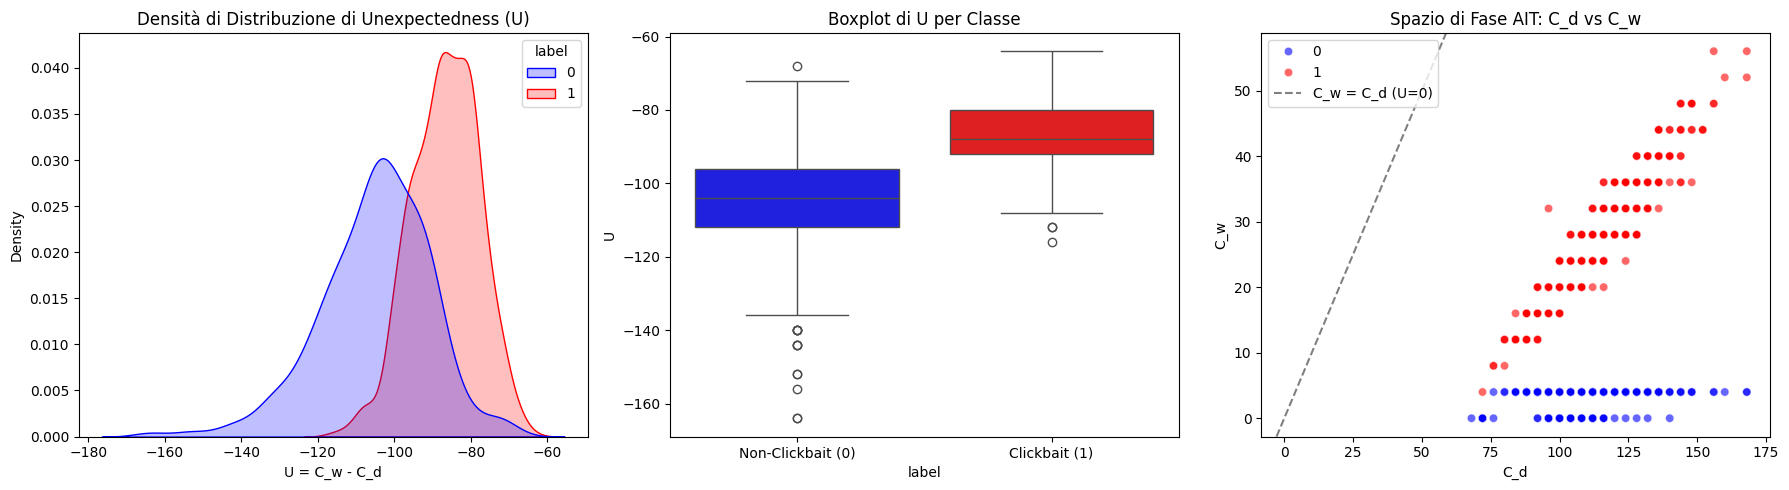


--> Soglia ottimale trovata su Train Set: U* = -103.9599 (Train F1: 0.8071)

BENCHMARK COMPARATIVO SUL TEST SET
                       Modello  Accuracy  F1-Score  ROC-AUC
    AIT Detector (U-threshold)    0.7633    0.8022   0.7633
   Random Classifier (Uniform)    0.5100    0.5084   0.5100
Random Classifier (Stratified)    0.5133    0.5034   0.5133
  Logistic Regression (TF-IDF)    0.8800    0.8792   0.8800

Report Dettagliato Classificatore AIT:
              precision    recall  f1-score   support

  Legitimate       0.93      0.57      0.71       150
   Clickbait       0.69      0.96      0.80       150

    accuracy                           0.76       300
   macro avg       0.81      0.76      0.75       300
weighted avg       0.81      0.76      0.75       300



In [14]:
import lzma
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# =====================================================================
# 1. CLASSE DI CALCOLO COMPLESSITÀ ED UNEXPECTEDNESS (AIT)
# =====================================================================
class AITComplexityEngine:
    def __init__(self, background_corpus: str):
        """
        Inizializza il motore AIT con un corpus di background (World Knowledge).
        """
        self.world_knowledge = background_corpus.encode('utf-8')
        # Pre-compressione del background per calcolare C_w marginale
        self.compressed_world_size = len(lzma.compress(self.world_knowledge))

    def get_cd(self, text: str) -> int:
        """
        Complessità descrittiva C_d: Z(text)
        """
        return len(lzma.compress(text.encode('utf-8')))

    def get_cw(self, text: str) -> int:
        """
        Complessità causale approssimata C_w: Z(World + text) - Z(World)
        """
        combined = self.world_knowledge + b" " + text.encode('utf-8')
        return max(len(lzma.compress(combined)) - self.compressed_world_size, 0)

    def compute_metrics(self, text: str) -> tuple:
        cd = self.get_cd(text)
        cw = self.get_cw(text)
        u = cw - cd
        # Unexpectedness normalizzata sulla lunghezza (evita bias di string length)
        u_norm = u / (len(text) + 1e-5)
        return cd, cw, u, u_norm


# =====================================================================
# 2. CARICAMENTO E PREPARAZIONE DEL DATASET
# =====================================================================
print("--> Caricamento del dataset da Hugging Face...")
raw_dataset = load_dataset("christinacdl/clickbait_detection_dataset", split="train")
df_raw = pd.DataFrame(raw_dataset)

# Riconoscimento automatico delle colonne per testo e target
text_col = 'text' if 'text' in df_raw.columns else ('headline' if 'headline' in df_raw.columns else df_raw.columns[0])
label_col = 'label' if 'label' in df_raw.columns else df_raw.columns[1]

# Campionamento bilanciato per garantire tempi di calcolo riproducibili e corretti
SAMPLE_SIZE = 1000  # 500 clickbait e 500 non-clickbait
df_cb = df_raw[df_raw[label_col] == 1].sample(SAMPLE_SIZE // 2, random_state=42)
df_non_cb = df_raw[df_raw[label_col] == 0].sample(SAMPLE_SIZE // 2, random_state=42)
df = pd.concat([df_cb, df_non_cb]).sample(frac=1.0, random_state=42).reset_index(drop=True)

# Costruzione del corpus di "World Knowledge": usiamo una porzione di notizie legittime
world_reference_text = " ".join(df_non_cb[text_col].head(8000).tolist())
engine = AITComplexityEngine(background_corpus=world_reference_text)

print(f"--> Elaborazione di {len(df)} istanze per estrazione delle feature AIT...")
cd_list, cw_list, u_list, unorm_list = [], [], [], []

for text in df[text_col]:
    cd, cw, u, u_norm = engine.compute_metrics(str(text))
    cd_list.append(cd)
    cw_list.append(cw)
    u_list.append(u)
    unorm_list.append(u_norm)

df['C_d'] = cd_list
df['C_w'] = cw_list
df['U'] = u_list
df['U_norm'] = unorm_list


# =====================================================================
# 3. REQUISITO 1: EXPLORATORY DATA ANALYSIS (CORRELAZIONE E TEST)
# =====================================================================
print("\n" + "="*50)
print("EXPLORATORY DATA ANALYSIS: UNEXPECTEDNESS vs CLICKBAIT")
print("="*50)

# Statistiche per classe
summary = df.groupby(label_col)[['C_d', 'C_w', 'U', 'U_norm']].agg(['mean', 'std', 'median'])
print(summary.to_string())

# Correlazioni
corr_pearson, p_pearson = stats.pearsonr(df['U'], df[label_col])
corr_spearman, p_spearman = stats.spearmanr(df['U'], df[label_col])
t_stat, t_pval = stats.ttest_ind(df[df[label_col] == 1]['U'], df[df[label_col] == 0]['U'])

print(f"\nPearson Correlation (U, Label):  {corr_pearson:.4f} (p-value: {p_pearson:.4e})")
print(f"Spearman Correlation (U, Label): {corr_spearman:.4f} (p-value: {p_spearman:.4e})")
print(f"Two-sample t-test su U: t = {t_stat:.4f}, p-value = {t_pval:.4e}")

# Visualizzazioni grafiche
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Creiamo una palette unificata che mappa sia gli interi che le stringhe per sicurezza
safe_palette = {0: 'blue', 1: 'red', '0': 'blue', '1': 'red'}

# Plot 1: Distribuzione di U
sns.kdeplot(data=df, x='U', hue=label_col, common_norm=False, fill=True, palette=safe_palette, ax=axes[0])
axes[0].set_title("Densità di Distribuzione di Unexpectedness (U)")
axes[0].set_xlabel("U = C_w - C_d")

# Plot 2: Boxplot U (Corretto con hue e legend=False)
sns.boxplot(data=df, x=label_col, y='U', hue=label_col, palette=safe_palette, legend=False, ax=axes[1])
axes[1].set_xticklabels(["Non-Clickbait (0)", "Clickbait (1)"])
axes[1].set_title("Boxplot di U per Classe")

# Plot 3: Spazio C_d vs C_w
sns.scatterplot(data=df, x='C_d', y='C_w', hue=label_col, alpha=0.6, palette=safe_palette, ax=axes[2])
axes[2].axline((0, 0), slope=1, color='gray', linestyle='--', label='C_w = C_d (U=0)')
axes[2].set_title("Spazio di Fase AIT: C_d vs C_w")
axes[2].legend()

plt.tight_layout()
plt.show()


# =====================================================================
# 4. REQUISITO 2: DETECTOR AIT BASATO SU SOGLIA DI OTTIMIZZAZIONE
# =====================================================================
train_df, test_df = train_test_split(df, test_size=0.3, random_state=42, stratify=df[label_col])

# Ricerca della soglia U* che massimizza l'F1-score sul train set (pure AIT)
thresholds = np.linspace(train_df['U'].min(), train_df['U'].max(), 300)
best_threshold = None
best_f1 = -1.0

for t in thresholds:
    preds = (train_df['U'] >= t).astype(int)
    score = f1_score(train_df[label_col], preds, zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_threshold = t

print(f"\n--> Soglia ottimale trovata su Train Set: U* = {best_threshold:.4f} (Train F1: {best_f1:.4f})")

# Predizione sul test set
test_preds_ait = (test_df['U'] >= best_threshold).astype(int)


# =====================================================================
# 5. REQUISITO 3: BENCHMARK CONTRO MODELLI DI RIFERIMENTO
# =====================================================================

# Modello Random Uniforme (Mancava nel tuo snippet)
dummy_uniform = DummyClassifier(strategy="uniform", random_state=42)
dummy_uniform.fit(train_df[['U']], train_df[label_col])
preds_uniform = dummy_uniform.predict(test_df[['U']])

# Modello Random Stratificato
dummy_strat = DummyClassifier(strategy="stratified", random_state=42)
dummy_strat.fit(train_df[['U']], train_df[label_col])
preds_strat = dummy_strat.predict(test_df[['U']])

# 2. Modello NLP Tradizionale (TF-IDF + Logistic Regression)
tfidf = TfidfVectorizer(max_features=3000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(train_df[text_col].astype(str))
X_test_tfidf = tfidf.transform(test_df[text_col].astype(str))

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_tfidf, train_df[label_col])
preds_lr = lr_model.predict(X_test_tfidf)

# Tabella comparativa delle metriche (Aggiunto il modello NLP)
models = {
    "AIT Detector (U-threshold)": test_preds_ait,
    "Random Classifier (Uniform)": preds_uniform,
    "Random Classifier (Stratified)": preds_strat,
    "Logistic Regression (TF-IDF)": preds_lr
}

benchmark_records = []
y_test = test_df[label_col]

for name, preds in models.items():
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    roc = roc_auc_score(y_test, preds)
    benchmark_records.append({
        "Modello": name,
        "Accuracy": round(acc, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4)
    })

df_benchmark = pd.DataFrame(benchmark_records)

print("\n" + "="*50)
print("BENCHMARK COMPARATIVO SUL TEST SET")
print("="*50)
print(df_benchmark.to_string(index=False))

print("\nReport Dettagliato Classificatore AIT:")
print(classification_report(y_test, test_preds_ait, target_names=["Legitimate", "Clickbait"]))

In [13]:
Modello Accuracy F1-Score ROC-AUC

AIT Detector (U-threshold) 0.6467 0.7310 0.6467

Random Classifier (Uniform) 0.5100 0.5084 0.5100

Random Classifier (Stratified) 0.5133 0.5034 0.5133



Report Dettagliato Classificatore AIT:

precision recall f1-score support



Legitimate 0.89 0.33 0.49 150

Clickbait 0.59 0.96 0.73 150



accuracy 0.65 300

macro avg 0.74 0.65 0.61 300

weighted avg 0.74 0.65 0.61 300



SyntaxError: invalid syntax (3906946611.py, line 1)